# Sea Surface Temperature

Projected annual mean sea surface temperature (`tos`) from the CSIRO CMIP6 multi-model ensemble, averaged over the selected country's EEZ and at the grid cell nearest to the site.

```{glue:figure} eez_box_fig
:scale: 60%
:align: right
```

**Figure. EEZ-average SST at global warming levels.** Each box shows the spread across models in the year each scenario first reaches the level.

In [1]:
# CIndRA notebook display standard
import matplotlib as mpl

mpl.rcParams.update({
    'font.size': 12,
    'axes.titlesize': 15,
    'axes.labelsize': 14,
    'xtick.labelsize': 12,
    'ytick.labelsize': 12,
    'legend.fontsize': 13,
    'figure.dpi': 100,
    'savefig.dpi': 150,
})

## Setup

Import libraries and helper functions. Projection plotting utilities come from the [indicators_setup](https://github.com/lauracagigal/indicators_setup) repository (`ind_setup.plotting_projections`); data access, site configuration and output helpers come from `functions/projections.py` and `functions/site_common.py`.

In [2]:
import warnings
warnings.filterwarnings("ignore")

import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from myst_nb import glue

sys.path.append("../../../../../../indicators_setup")
from ind_setup.plotting_projections import plot_projection_palau, get_box_data, plot_global_warming_boxplot

sys.path.append("../../../../functions")
from site_common import load_site_config, list_available_sites, site_config_filename, build_site_tag, build_site_figures_dir, build_site_tables_dir
import projections as prj

### Define location

Set `site_key` to one of the sites configured with [`../../../historical/National/00_site_setup.ipynb`](../../../historical/National/00_site_setup.ipynb) (see the list printed below). The notebook reads the coordinates and country from `data/sites/<site_key>.json`, exactly as the historical notebooks do.

In [3]:
sites_dir = Path("../../../../data/sites")
available_sites = list_available_sites(sites_dir)
print(f"{len(available_sites)} site(s) already configured in {sites_dir}:")
display(available_sites)

6 site(s) already configured in ../../../../data/sites:


,site_key,site_name,country,ghcn_station_id,ghcn_station_name,vars_interest
0,cook_islands_new_zealand_cwm00091843,cook_islands_new_zealand_CWM00091843,Cook Islands [New Zealand],CWM00091843,RAROTONGA INTL GSN 91843,"[TMIN, TMAX, PRCP]"
1,marshall_islands_rmw00040604,marshall_islands_RMW00040604,Marshall Islands,RMW00040604,MH KWAJALEIN GSN 91366,"[TMIN, TMAX, PRCP]"
2,marshall_islands_rmw00040710,marshall_islands_RMW00040710,Marshall Islands,RMW00040710,MH MAJURO WBAS AP GSN 91376,"[TMIN, TMAX, PRCP]"
3,niue_new_zealand_nem00091824,niue_new_zealand_NEM00091824,Niue [New Zealand],NEM00091824,HANAN AIRPORT GSN 91824,"[TMIN, TMAX, PRCP]"
4,palau,Palau,Palau,None,None,None
5,palau_psw00040309,palau_PSW00040309,Palau,PSW00040309,PW KOROR GSN 91408,"[TMIN, TMAX, PRCP]"


In [4]:
site_key = "palau_psw00040309"  # pick a site_key from the table printed above

site_cfg = load_site_config(sites_dir / site_config_filename(site_key))

site_name = site_cfg.get("site_name", "Site")
site_lon = float(site_cfg["site_lon"])
site_lat = float(site_cfg["site_lat"])
country = site_cfg.get("country", site_name)
site_label = country

site_tag = build_site_tag(site_name, site_lon, site_lat)
fig_dir = build_site_figures_dir(Path("../../../../outputs"), site_name, site_lon, site_lat)
tables_dir = build_site_tables_dir(Path("../../../../outputs"), site_name, site_lon, site_lat)
cache_dir = prj.site_cache_dir(site_tag)
print(f"{country}: lon {site_lon}, lat {site_lat} -> figures in {fig_dir}")

Palau: lon 134.4769, lat 7.3367 -> figures in ../../../../outputs/figures/palau_psw00040309_lat7p337_lon134p477


### Scenarios and global warming levels

Years at which the IPCC AR6 multi-model mean global surface temperature first reaches each warming level (°C above 1850–1900), computed in [`../00_warming_levels.ipynb`](../00_warming_levels.ipynb). Local values are read from every model at those years.

In [5]:
ssp_scenarios = ['ssp126', 'ssp245', 'ssp370', 'ssp585']
incr_temps = list(prj.WARMING_LEVELS)
delta_t = 0  # warming levels are already expressed relative to 1850–1900

scenario_info = prj.load_warming_levels(ssp_scenarios)
pd.DataFrame({sc: {f"+{wl}°C": info["year"] for wl, info in levels.items()} for sc, levels in scenario_info.items()})

,ssp126,ssp245,ssp370,ssp585
+1.5°C,2032-01-01,2030-01-01,2030-01-01,2027-01-01
+2.0°C,NaT,2052-01-01,2046-01-01,2041-01-01
+2.5°C,NaT,2079-01-01,2061-01-01,2053-01-01
+3.0°C,NaT,NaT,2075-01-01,2064-01-01


### Get data

Monthly SST from the CSIRO CMIP6 ensemble on the common 1° grid, averaged to annual means. The EEZ average uses cosine-of-latitude weights over the grid cells whose centre falls inside the EEZ (`data/regional/Pacific_EEZs`). Both series are cached under `data/projections/<site_tag>/`.

In [6]:
eez_geometry = prj.site_eez(country)
ds_eez = prj.extract_eez_mean("tos", eez_geometry, ssp_scenarios, cache_file=cache_dir / "tos_eez.nc")
ds_point = prj.extract_point("tos", site_lon, site_lat, ssp_scenarios, cache_file=cache_dir / "tos_point.nc")
print(f"EEZ grid cells: {ds_eez.attrs['n_cells']}; point cell: lon {ds_point.attrs['grid_lon']}, lat {ds_point.attrs['grid_lat']}")

EEZ grid cells: 49; point cell: lon 134.0, lat 7.0


## Analysis

### EEZ average

PosixPath('../../../../outputs/figures/palau_psw00040309_lat7p337_lon134p477/PRJ_sst_eez_timeseries_palau_psw00040309_lat7p337_lon134p477.png')

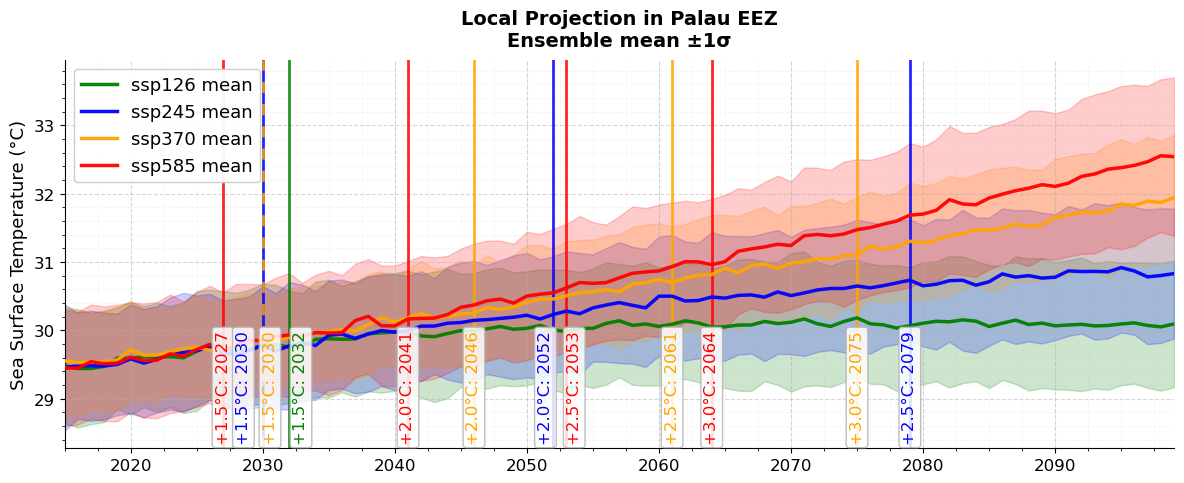

In [7]:
fig, ax = plot_projection_palau(ds_eez, "tos", scenario_info, ssp_scenarios, delta_t=delta_t, site_label=f"{site_label} EEZ")
prj.save_figure(fig, fig_dir, "sst_eez_timeseries", site_tag)

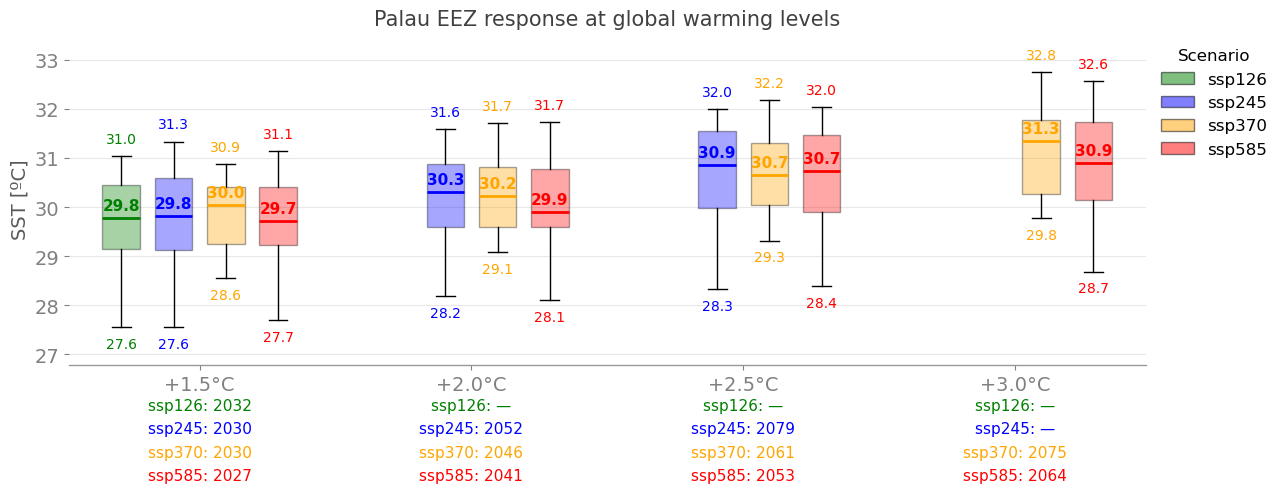

In [8]:
box_data, box_scenarios, positions = get_box_data(ds_eez, scenario_info, incr_temps, ssp_scenarios, "tos")
fig, ax = plot_global_warming_boxplot(box_data, ds_eez, positions, box_scenarios, scenario_info, incr_temps, "tos",
                                      plot_ref=False, n_f=1, delta_t=delta_t, site_label=f"{site_label} EEZ")
prj.save_figure(fig, fig_dir, "sst_eez_gwl", site_tag)
glue("eez_box_fig", fig, display=False)

In [9]:
table = prj.gwl_summary(ds_eez, "tos", scenario_info, ssp_scenarios, decimals=2)
prj.save_table(table, tables_dir, "sst_eez_gwl", site_tag)
table

,Scenario,Warming level,Year,Models,Median,P10,P90,Min,Max
0,SSP126,+1.5°C,2032,35,29.78,28.87,30.78,27.56,31.05
1,SSP126,+2.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
2,SSP126,+2.5°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
3,SSP126,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
4,SSP245,+1.5°C,2030,35,29.82,28.68,30.83,27.56,31.34
5,SSP245,+2.0°C,2052,35,30.30,29.30,31.40,28.19,31.60
6,SSP245,+2.5°C,2079,35,30.86,29.74,31.72,28.33,32.00
7,SSP245,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
8,SSP370,+1.5°C,2030,33,30.04,29.02,30.68,28.56,30.88
9,SSP370,+2.0°C,2046,33,30.23,29.40,31.18,29.08,31.71


### Site

PosixPath('../../../../outputs/figures/palau_psw00040309_lat7p337_lon134p477/PRJ_sst_point_timeseries_palau_psw00040309_lat7p337_lon134p477.png')

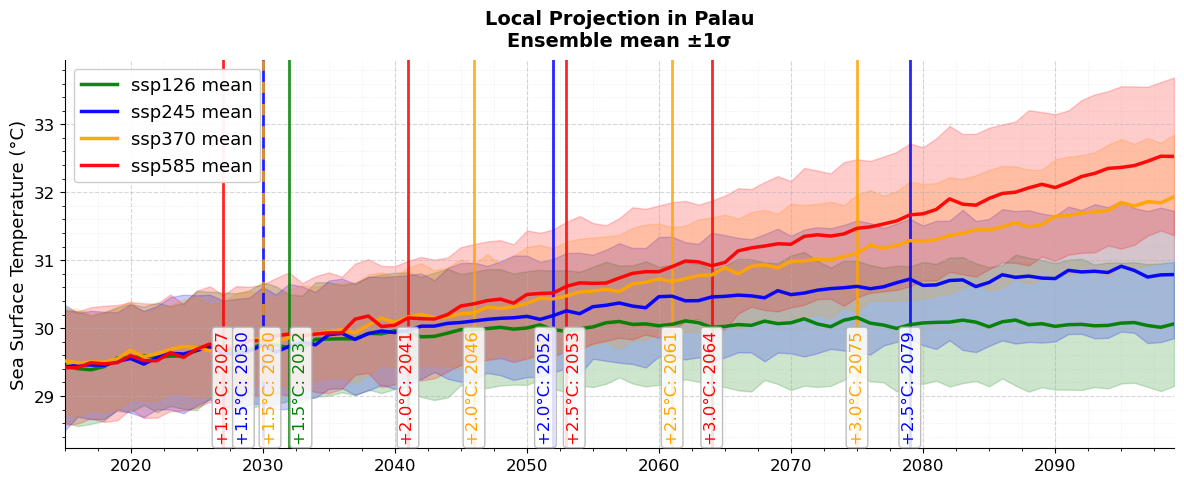

In [10]:
fig, ax = plot_projection_palau(ds_point, "tos", scenario_info, ssp_scenarios, delta_t=delta_t, site_label=site_label)
prj.save_figure(fig, fig_dir, "sst_point_timeseries", site_tag)

PosixPath('../../../../outputs/figures/palau_psw00040309_lat7p337_lon134p477/PRJ_sst_point_gwl_palau_psw00040309_lat7p337_lon134p477.png')

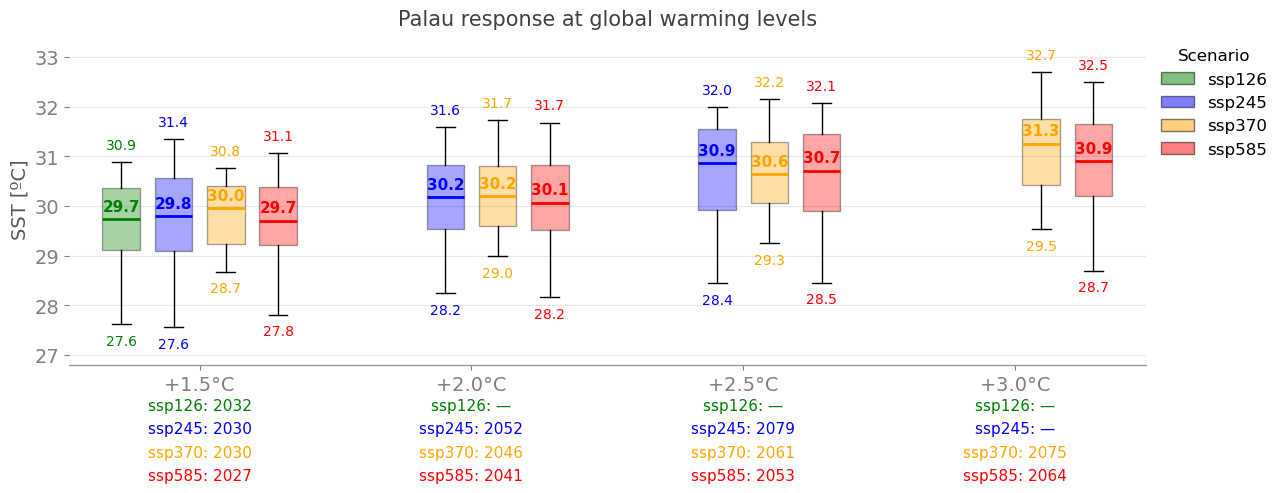

In [11]:
box_data, box_scenarios, positions = get_box_data(ds_point, scenario_info, incr_temps, ssp_scenarios, "tos")
fig, ax = plot_global_warming_boxplot(box_data, ds_point, positions, box_scenarios, scenario_info, incr_temps, "tos",
                                      plot_ref=False, n_f=1, delta_t=delta_t, site_label=site_label)
prj.save_figure(fig, fig_dir, "sst_point_gwl", site_tag)

In [12]:
table = prj.gwl_summary(ds_point, "tos", scenario_info, ssp_scenarios, decimals=2)
prj.save_table(table, tables_dir, "sst_point_gwl", site_tag)
table

,Scenario,Warming level,Year,Models,Median,P10,P90,Min,Max
0,SSP126,+1.5°C,2032,35,29.73,28.84,30.72,27.62,30.88
1,SSP126,+2.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
2,SSP126,+2.5°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
3,SSP126,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
4,SSP245,+1.5°C,2030,35,29.79,28.60,30.74,27.56,31.36
5,SSP245,+2.0°C,2052,35,30.19,29.22,31.33,28.24,31.59
6,SSP245,+2.5°C,2079,35,30.86,29.78,31.76,28.44,31.99
7,SSP245,+3.0°C,<NA>,0,NaN,NaN,NaN,NaN,NaN
8,SSP370,+1.5°C,2030,33,29.96,28.94,30.66,28.68,30.76
9,SSP370,+2.0°C,2046,33,30.20,29.34,31.18,29.00,31.73
